## Cargar los datos ##

In [19]:
import numpy as np
import pandas as pd

In [20]:
df = pd.read_csv('data/GenreAll.csv', skipinitialspace=True)

# eliminar filas que no tienen género
df = df.dropna(subset=['genre']) 

#feature que queremos predecir
y = df['genre'] 

#features para el entrenamiento
X = df.drop(columns=["genre"]).copy()

# Convertir columnas binarias de texto en 0 y 1
text_columns = X.select_dtypes(include=['str', 'object', 'string']).columns

for col in text_columns:
    values = X[col].dropna().unique()

    if len(values) == 2:
        X[col] = X[col].map({
            values[0]: 0,
            values[1]: 1})
            
#asegurar que solo hay valores numéricos
X = X.select_dtypes(include=np.number)

print("Número de canciones:", len(df))
print("Número de features:", X.shape[1])
print("\nCanciones por género:")
print(y.value_counts())

df.head()

Número de canciones: 993
Número de features: 240

Canciones por género:
genre
blu    100
cou    100
dis    100
hip    100
jaz    100
met    100
pop    100
reg    100
roc    100
cla     93
Name: count, dtype: int64


,highlevel_danceability_value,highlevel_equalization_profile_value,highlevel_excitement_value,highlevel_intensity_value,highlevel_speech_music_value,highlevel_voice_instrumental_value,loudness_dynamic_complexity_dvar,loudness_dynamic_complexity_mean,loudness_dynamic_complexity_var,loudness_larm_dvar,...,tonal_chords_strength_dvar,tonal_chords_strength_mean,tonal_chords_strength_var,tonal_dissonance_dvar,tonal_dissonance_mean,tonal_dissonance_var,tonal_key_mode_value,tonal_key_strength_value,tonal_tuning_equal_tempered_deviation_value,genre
0,0.477744,0.372766,0.029087,0.093526,speech,instrumental,-0.366526,0.832351,-0.398487,0.262413,...,0.175405,0.101673,0.989475,0.167484,-0.091051,0.085449,major,0.162259,2.423830,blu
1,0.271161,0.372766,-1.283803,-0.615420,speech,voice,0.275184,1.901008,-0.287263,0.078360,...,-0.157583,-0.652126,-0.992276,0.606661,-0.468630,0.416914,major,0.230571,-0.207952,blu
2,0.089011,0.372766,0.029087,1.511419,music,instrumental,-0.177390,0.046932,0.035041,-0.157974,...,-0.001059,-0.220255,0.978014,-0.236338,0.470580,-0.205887,major,1.024735,-0.211034,blu
3,0.243503,0.372766,0.029087,-0.615420,music,instrumental,-0.319420,-0.953075,0.239607,-0.659566,...,0.214463,0.853728,1.327351,-0.542341,0.642223,-0.791110,major,0.079033,0.148357,blu
4,0.594883,-1.940715,-1.283803,0.093526,speech,instrumental,-0.224956,1.154507,-0.420087,0.281666,...,-0.140930,-0.080519,-1.163700,0.094741,-0.164770,-0.277919,major,-0.337966,-0.277459,blu


## Definición de los modelos ##

Un pipeline es una cadena de pasos que se ejecutan en orden. Por ejemplo, antes de entrenar un modelo, podemos necesitar rellenar datos que faltan y normalizar las características.

`Pipeline` permite crear un pipeline combinando varios pasos

`SimpleImputer` sirve para rellenar los valores que faltan en los datos, por ejemplo, cuando una característica musical contiene NaN. se puede usar `StandardScaler` para rellenar esos datos vacíos

In [21]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

#modelos
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier

In [22]:
models = {
    "Logistic Regression": (
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("model", LogisticRegression(max_iter=2000))
        ]),
        {
            "model__C": [0.01, 0.03, 0.1, 0.3, 1]
        }
    ),

    "k-NN": (
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("model", KNeighborsClassifier())
        ]),
        {
            "model__n_neighbors": [3, 5, 7, 9, 13, 17],
            "model__weights": ["uniform", "distance"],
            "model__p": [1, 2]
        }
    ),

    "Decision Tree": (
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", DecisionTreeClassifier(random_state=42))
        ]),
        {
            "model__max_depth": [5, 10, 15],
            "model__min_samples_split": [5, 10],
            "model__min_samples_leaf": [5, 10]
        }
    ),

    "Artificial Neural Network": (
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("model", MLPClassifier(
                max_iter=500,
                random_state=42,
                early_stopping=False,
                n_iter_no_change=15,
                tol=1e-3
            ))
        ]),
        {
            "model__hidden_layer_sizes": [(30,), (50,), (100,), (50, 25)],
            "model__alpha": [0.01, 0.1, 1.0]
        }
    )
}

## Definir la validación cruzada
 
Mismo esquema de 10 folds para comparar todos los algoritmos

In [23]:
from sklearn.model_selection import StratifiedKFold

In [24]:
cv = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=42)

## Entrenar y evaluar los modelos

Esta es la celda principal. `GridSearchCV` probará todas las configuraciones usando validación cruzada de 10 folds y seleccionará la que obtenga la mejor accuracy media para cada algoritmo

In [30]:
from sklearn.model_selection import GridSearchCV

In [ ]:

results = []
best_models = {}

for name, (pipeline, params) in models.items():

    print("\nEvaluando:", name)

    search = GridSearchCV(
        estimator=pipeline,
        param_grid=params,
        scoring="accuracy",
        cv=cv,
        return_train_score=True,
        n_jobs=-1)

    search.fit(X, y)

    best_models[name] = search

    # Guardar los resultados de todas las configuraciones
    for i in range(len(search.cv_results_["params"])):
        results.append({
            "Algorithm": name,
            "Parameters": search.cv_results_["params"][i],
            "Train accuracy": search.cv_results_["mean_train_score"][i],
            "CV accuracy": search.cv_results_["mean_test_score"][i]})

    # Seleccionar la configuración con mayor accuracy
    # entre las que tienen overfitting < 0.15
    cv_results = pd.DataFrame(search.cv_results_)

    cv_results["Overfitting gap"] = (cv_results["mean_train_score"] - cv_results["mean_test_score"])

    valid_results = cv_results[cv_results["Overfitting gap"] < 0.15]

    #si no se alcanza el objetivo de ovefitting menor que 0,15, busca el que más ccuracy tenga directamente
    if not valid_results.empty:
        best_row = valid_results.sort_values("mean_test_score", ascending=False).iloc[0]
    else:
        best_row = cv_results.sort_values("mean_test_score", ascending=False).iloc[0]

    print("Best parameters:", best_row["params"])
    print("Best 10-fold CV accuracy (without overfitting):", round(best_row["mean_test_score"], 4))
    print("Overfitting gap:", round(best_row["Overfitting gap"], 4))
    print("Overfitting ok:", best_row["Overfitting gap"] < 0.15)

results_df = pd.DataFrame(results)

results_df["Overfitting gap"] = (
    results_df["Train accuracy"] -
    results_df["CV accuracy"]
)

results_df["Acceptable accuracy"] = (
    (results_df["CV accuracy"] > 0.70) 
)

results_df["Acceptable overfitting"] = (
    results_df["Overfitting gap"] < 0.15
)
results_df["Fits objectives"] = (
    (results_df["Overfitting gap"] < 0.15) & 
    (results_df["CV accuracy"] > 0.70)
)

results_df = results_df.sort_values(
    ["Acceptable overfitting", "CV accuracy", "Overfitting gap"],
    ascending=[False, False, True]
).reset_index(drop=True)

print(f"Total configs evaluated: {len(results_df)}")
print(f"Configs with appropiate overfitting: "
      f"{results_df['Acceptable overfitting'].sum()}")
print(f"Configs with both good accuracy and overfitting: "
      f"{results_df['Fits objectives'].sum()}")

display(results_df)


Evaluando: Logistic Regression


Best parameters: {'model__C': 0.1}
Best 10-fold CV accuracy (without overfitting): 0.8408
Overfitting gap: 0.1437
Overfitting ok: True

Evaluando: k-NN
Best parameters: {'model__n_neighbors': 5, 'model__p': 1, 'model__weights': 'uniform'}
Best 10-fold CV accuracy (without overfitting): 0.7391
Overfitting gap: 0.0911
Overfitting ok: True

Evaluando: Decision Tree
Best parameters: {'model__max_depth': 10, 'model__min_samples_leaf': 10, 'model__min_samples_split': 5}
Best 10-fold CV accuracy (without overfitting): 0.6283
Overfitting gap: 0.1482
Overfitting ok: True

Evaluando: Artificial Neural Network
Best parameters: {'model__alpha': 1.0, 'model__hidden_layer_sizes': (100,)}
Best 10-fold CV accuracy (without overfitting): 0.8499
Overfitting gap: 0.1484
Overfitting ok: True
Total configs evaluated: 53
Configs with appropiate overfitting: 22
Configs with both good accuracy and overfitting: 15


,Algorithm,Parameters,Train accuracy,CV accuracy,Overfitting gap,Acceptable accuracy,Acceptable overfitting,Fits objectives
0,Artificial Neural Network,"{'model__alpha': 1.0, 'model__hidden_layer_siz...",0.998322,0.849919,0.148402,True,True,True
1,Logistic Regression,{'model__C': 0.1},0.984558,0.840848,0.143710,True,True,True
2,Logistic Regression,{'model__C': 0.03},0.950766,0.829788,0.120978,True,True,True
3,Logistic Regression,{'model__C': 0.01},0.892245,0.805606,0.086639,True,True,True
4,k-NN,"{'model__n_neighbors': 5, 'model__p': 1, 'mode...",0.830143,0.739091,0.091052,True,True,True
5,k-NN,"{'model__n_neighbors': 5, 'model__p': 2, 'mode...",0.814142,0.731030,0.083112,True,True,True
6,k-NN,"{'model__n_neighbors': 9, 'model__p': 1, 'mode...",0.790533,0.728949,0.061583,True,True,True
7,k-NN,"{'model__n_neighbors': 3, 'model__p': 1, 'mode...",0.862370,0.727949,0.134421,True,True,True
8,k-NN,"{'model__n_neighbors': 7, 'model__p': 1, 'mode...",0.810897,0.723919,0.086978,True,True,True
9,k-NN,"{'model__n_neighbors': 3, 'model__p': 2, 'mode...",0.859460,0.723010,0.136450,True,True,True


Select the configuration you want to plot a as a confusion matrix (row number).

Selected algorithm: Artificial Neural Network
Parameters: {'model__alpha': 1.0, 'model__hidden_layer_sizes': (100,)}
CV accuracy: 0.8499
Overfitting gap: 0.1484


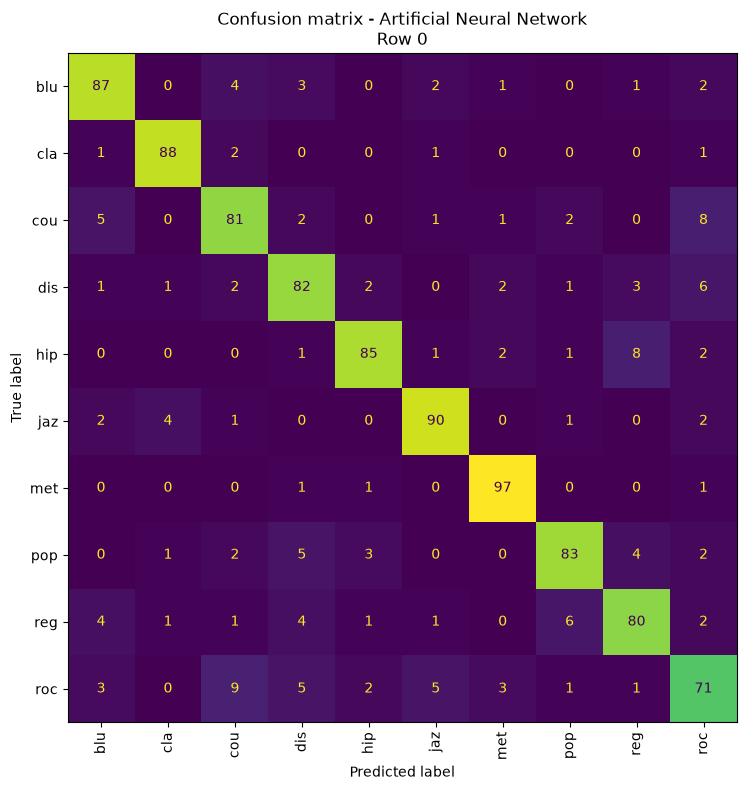

In [41]:

from sklearn.base import clone
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Seleccionar una fila de la tabla ordenada
num_rows = len(results_df)

print("Select the configuration you want to plot a as a confusion matrix (row number).")
row = int(input(f"Introduce a number between 0 y {num_rows - 1}: "))

if row < 0 or row > num_rows:
    raise ValueError(f"Row number must be between 0 and {num_rows}.")

# Obtener la configuración elegida
selected_row = results_df.iloc[row]
name = selected_row["Algorithm"]
params = selected_row["Parameters"]

print(f"\nSelected algorithm: {name}")
print(f"Parameters: {params}")
print(f"CV accuracy: {selected_row['CV accuracy']:.4f}")
print(f"Overfitting gap: {selected_row['Overfitting gap']:.4f}")

# Reconstruir el pipeline con los parámetros seleccionados
pipeline, _ = models[name]
selected_model = clone(pipeline)
selected_model.set_params(**params)

# Obtener predicciones out-of-fold mediante validación cruzada.
# Cada muestra se predice con un modelo que no la ha utilizado para entrenar.
y_pred = cross_val_predict(
    selected_model,
    X,
    y,
    cv=cv,
    n_jobs=-1
)

# Matriz de confusión
classes = np.unique(y)

cm = confusion_matrix(y, y_pred, labels=classes)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=classes
)

fig, ax = plt.subplots(figsize=(10, 8))
disp.plot(
    ax=ax,
    xticks_rotation="vertical",
    values_format="d",
    colorbar=False
)

ax.set_title(f"Confusion matrix - {name}\nRow {row}")
plt.tight_layout()
plt.show()
